# Jan-Samadhan: Smart Citizen Grievance Redressal & Policy Assistant

**Trainee:** Akhilesh Jaiswal  
**Program:** GOT-A  
**Dataset:** 500-row synthetic citizen grievance dataset

This project demonstrates data analysis, machine learning-based complaint routing, Generative AI prompt engineering, and privacy-preserving grievance processing.

**Note:** All grievance records are synthetically generated for educational purposes. They are not actual citizen complaints.

In [1]:

import pandas as pd
import numpy as np
import random
from pathlib import Path

# Reproducibility
random.seed(42)
np.random.seed(42)

# Project directories
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# Synthetic complaint templates
complaints = {
    "Water Supply": [
        "There has been no water supply in our locality for several days.",
        "The drinking water pipeline is leaking and wasting water.",
        "Water pressure is very low in our residential area.",
        "The supplied water is dirty and not suitable for drinking.",
        "Our village hand pump is not working and needs repair."
    ],
    "Electricity": [
        "There has been a power outage in our locality for many hours.",
        "The electricity bill is unusually high despite low consumption.",
        "The electric transformer is damaged and needs immediate repair.",
        "Frequent power cuts are affecting residents and students.",
        "Our electricity connection application is still pending."
    ],
    "Public Distribution System": [
        "The ration shop is not distributing the full quantity of food grains.",
        "My ration card application has been pending for several months.",
        "The fair price shop dealer is refusing to provide subsidized ration.",
        "My name is missing from the ration card beneficiary list.",
        "The ration shop is demanding extra money for food grains."
    ],
    "Roads and Transport": [
        "The main road in our village is damaged and full of potholes.",
        "Road construction work has been incomplete for several months.",
        "The street has no proper drainage and becomes flooded during rain.",
        "The public bus service is irregular in our area.",
        "A damaged road is creating safety problems for commuters."
    ],
    "Municipal Services": [
        "Garbage has not been collected from our locality for many days.",
        "Street lights are not working and the road is dark at night.",
        "There is an overflowing drain near our residential area.",
        "The public park is not being maintained properly.",
        "Stray waste and sanitation problems are affecting our locality."
    ]
}

states = [
    "Uttar Pradesh", "Bihar", "Delhi", "Madhya Pradesh",
    "Rajasthan", "Uttarakhand", "Haryana", "Jharkhand"
]

records = []

departments = list(complaints.keys())

for department in departments:
    for i in range(100):

        complaint_text = random.choice(complaints[department])

        # Add synthetic variations
        extra_text = random.choice([
            "Please resolve this issue as soon as possible.",
            "Many families are facing difficulties.",
            "Kindly take necessary action.",
            "We have already complained but no action has been taken.",
            "This problem is affecting daily life."
        ])

        complaint_text = complaint_text + " " + extra_text

        # Add clearly synthetic phone numbers to some records
        if i % 10 == 0:
            complaint_text += " Contact number: 9000000000"

        submission_date = pd.Timestamp("2025-01-01") + pd.Timedelta(
            days=random.randint(0, 650)
        )

        status = random.choice([
            "Resolved", "Resolved", "Pending", "Under Process"
        ])

        if status == "Resolved":
            resolution_days = random.randint(1, 30)
        else:
            resolution_days = np.nan

        records.append({
            "complaint_id": f"JS-{len(records)+1:04d}",
            "state": random.choice(states),
            "submission_date": submission_date,
            "department": department,
            "category": department,
            "complaint_description": complaint_text,
            "status": status,
            "resolution_days": resolution_days
        })

# Create DataFrame and shuffle records
df = pd.DataFrame(records)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Save dataset
dataset_path = DATA_DIR / "jan_samadhan_grievances.csv"
df.to_csv(dataset_path, index=False)

print("JAN-SAMADHAN DATASET GENERATED SUCCESSFULLY")
print("-" * 50)
print("Total records:", len(df))
print("Total departments:", df["department"].nunique())
print("Dataset saved at:", dataset_path)
print("\nDepartment-wise complaint counts:")
print(df["department"].value_counts())
print("\nFirst five records:")
display(df.head())


JAN-SAMADHAN DATASET GENERATED SUCCESSFULLY
--------------------------------------------------
Total records: 500
Total departments: 5
Dataset saved at: C:\Users\sunny\Downloads\JAN_SAMADHAN\data\jan_samadhan_grievances.csv

Department-wise complaint counts:
department
Roads and Transport           100
Water Supply                  100
Electricity                   100
Municipal Services            100
Public Distribution System    100
Name: count, dtype: int64

First five records:


,complaint_id,state,submission_date,department,category,complaint_description,status,resolution_days
0,JS-0362,Rajasthan,2026-08-07,Roads and Transport,Roads and Transport,The public bus service is irregular in our are...,Resolved,12.0
1,JS-0074,Rajasthan,2025-10-13,Water Supply,Water Supply,The supplied water is dirty and not suitable f...,Resolved,25.0
2,JS-0375,Uttar Pradesh,2026-08-10,Roads and Transport,Roads and Transport,Road construction work has been incomplete for...,Resolved,7.0
3,JS-0156,Bihar,2026-05-21,Electricity,Electricity,Our electricity connection application is stil...,Under Process,NaN
4,JS-0105,Uttarakhand,2026-05-13,Electricity,Electricity,The electric transformer is damaged and needs ...,Resolved,13.0


In [2]:
# PHASE 1 - TASK 1.1: DATA EXPLORATION

import pandas as pd

# Load the generated dataset
df = pd.read_csv("data/jan_samadhan_grievances.csv")

# Convert submission_date into datetime format
df["submission_date"] = pd.to_datetime(df["submission_date"])

print("DATASET DIMENSIONS")
print("Rows and Columns:", df.shape)

print("\nCOLUMN INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all"))

print("\nSTRUCTURED AND UNSTRUCTURED COLUMNS")

structured_columns = [
    "complaint_id",
    "state",
    "submission_date",
    "department",
    "category",
    "status",
    "resolution_days"
]

unstructured_columns = [
    "complaint_description"
]

print("Structured columns:", structured_columns)
print("Unstructured columns:", unstructured_columns)

DATASET DIMENSIONS
Rows and Columns: (500, 8)

COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   complaint_id           500 non-null    object        
 1   state                  500 non-null    object        
 2   submission_date        500 non-null    datetime64[ns]
 3   department             500 non-null    object        
 4   category               500 non-null    object        
 5   complaint_description  500 non-null    object        
 6   status                 500 non-null    object        
 7   resolution_days        243 non-null    float64       
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 31.4+ KB

MISSING VALUES
complaint_id               0
state                      0
submission_date            0
department                 0
category                   0
complai

,complaint_id,state,submission_date,department,category,complaint_description,status,resolution_days
count,500,500,500,500,500,500,500,243.000000
unique,500,8,NaN,5,5,165,3,NaN
top,JS-0103,Madhya Pradesh,NaN,Roads and Transport,Roads and Transport,Stray waste and sanitation problems are affect...,Resolved,NaN
freq,1,67,NaN,100,100,11,243,NaN
mean,NaN,NaN,2025-12-04 02:15:21.599999744,NaN,NaN,NaN,NaN,15.530864
min,NaN,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,NaN,1.000000
25%,NaN,NaN,2025-07-01 06:00:00,NaN,NaN,NaN,NaN,8.500000
50%,NaN,NaN,2025-12-04 12:00:00,NaN,NaN,NaN,NaN,15.000000
75%,NaN,NaN,2026-05-21 12:00:00,NaN,NaN,NaN,NaN,23.000000
max,NaN,NaN,2026-10-12 00:00:00,NaN,NaN,NaN,NaN,30.000000



STRUCTURED AND UNSTRUCTURED COLUMNS
Structured columns: ['complaint_id', 'state', 'submission_date', 'department', 'category', 'status', 'resolution_days']
Unstructured columns: ['complaint_description']


In [3]:
# PHASE 1 - TASK 1.2: DATA CLEANING

import re
import pandas as pd

# Reload original dataset
df = pd.read_csv("data/jan_samadhan_grievances.csv")

# Convert date column
df["submission_date"] = pd.to_datetime(df["submission_date"])

# Check and remove duplicate records
duplicate_count = df.duplicated(subset=["complaint_id"]).sum()
df = df.drop_duplicates(subset=["complaint_id"])

# Clean complaint descriptions
def clean_text(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["complaint_description"] = (
    df["complaint_description"].apply(clean_text)
)

# Handle missing values in categorical/text columns
df["state"] = df["state"].fillna("Unknown")
df["department"] = df["department"].fillna("Unknown")
df["category"] = df["category"].fillna("Unknown")
df["complaint_description"] = (
    df["complaint_description"].fillna("")
)

# Keep missing resolution_days unchanged:
# These represent complaints not yet resolved.

# Save cleaned dataset
df.to_csv("data/jan_samadhan_cleaned.csv", index=False)

print("DATA CLEANING COMPLETED")
print("--------------------------------")
print("Total records after cleaning:", len(df))
print("Duplicate complaint IDs removed:", duplicate_count)
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nSample cleaned complaint descriptions:")
display(df[["complaint_id", "complaint_description"]].head())

print("\nCleaned dataset saved successfully.")

DATA CLEANING COMPLETED
--------------------------------
Total records after cleaning: 500
Duplicate complaint IDs removed: 0
Missing values after cleaning:
complaint_id               0
state                      0
submission_date            0
department                 0
category                   0
complaint_description      0
status                     0
resolution_days          257
dtype: int64

Sample cleaned complaint descriptions:


,complaint_id,complaint_description
0,JS-0362,The public bus service is irregular in our are...
1,JS-0074,The supplied water is dirty and not suitable f...
2,JS-0375,Road construction work has been incomplete for...
3,JS-0156,Our electricity connection application is stil...
4,JS-0105,The electric transformer is damaged and needs ...



Cleaned dataset saved successfully.


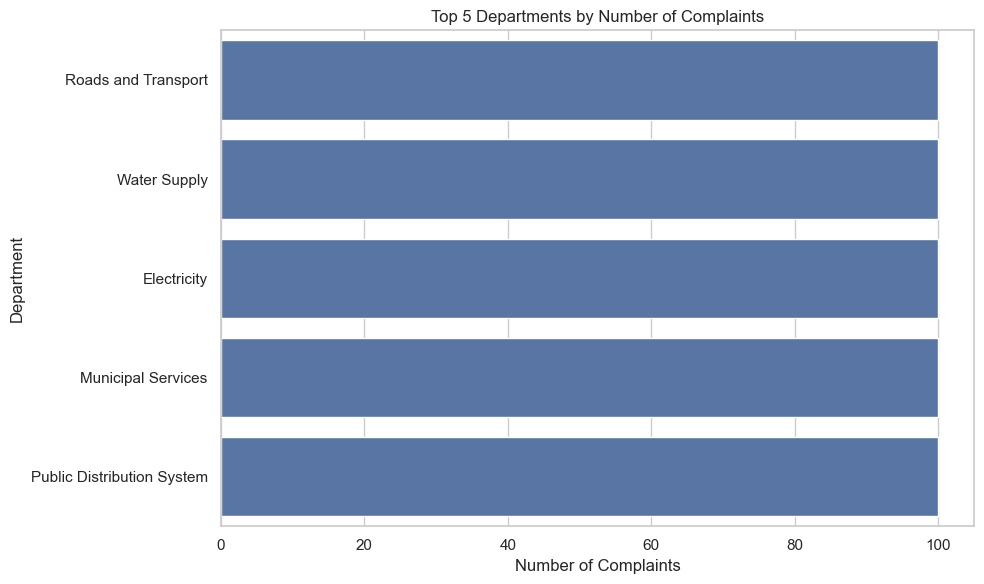

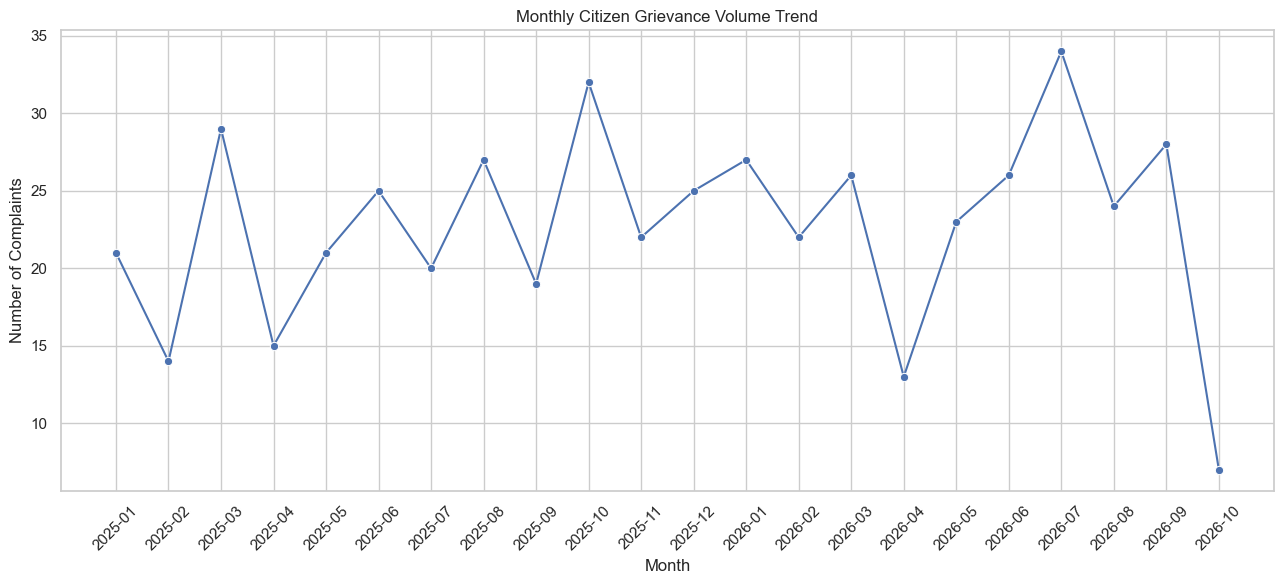

VISUALIZATION COMPLETED
----------------------------------

Department-wise complaint count:
department
Roads and Transport           100
Water Supply                  100
Electricity                   100
Municipal Services            100
Public Distribution System    100
Name: count, dtype: int64

Monthly complaint volume:


,month,complaint_count
0,2025-01,21
1,2025-02,14
2,2025-03,29
3,2025-04,15
4,2025-05,21
5,2025-06,25
6,2025-07,20
7,2025-08,27
8,2025-09,19
9,2025-10,32



Charts saved in outputs folder:
1. top_5_departments.png
2. monthly_complaint_trend.png


In [4]:
# PHASE 1 - TASK 1.3: DATA VISUALIZATION

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load cleaned dataset
df = pd.read_csv("data/jan_samadhan_cleaned.csv")

df["submission_date"] = pd.to_datetime(df["submission_date"])

# Create output directory
Path("outputs").mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

# --------------------------------------------------
# CHART 1: TOP 5 DEPARTMENTS BY COMPLAINT VOLUME
# --------------------------------------------------

department_counts = (
    df["department"]
    .value_counts()
    .head(5)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=department_counts.values,
    y=department_counts.index
)

plt.title("Top 5 Departments by Number of Complaints")
plt.xlabel("Number of Complaints")
plt.ylabel("Department")
plt.tight_layout()

plt.savefig(
    "outputs/top_5_departments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# CHART 2: MONTH-WISE COMPLAINT VOLUME TREND
# --------------------------------------------------

df["month"] = df["submission_date"].dt.to_period("M")

monthly_complaints = (
    df.groupby("month")
    .size()
    .reset_index(name="complaint_count")
)

monthly_complaints["month"] = (
    monthly_complaints["month"].astype(str)
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_complaints,
    x="month",
    y="complaint_count",
    marker="o"
)

plt.title("Monthly Citizen Grievance Volume Trend")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "outputs/monthly_complaint_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# SUMMARY
# --------------------------------------------------

print("VISUALIZATION COMPLETED")
print("----------------------------------")

print("\nDepartment-wise complaint count:")
print(department_counts)

print("\nMonthly complaint volume:")
display(monthly_complaints)

print("\nCharts saved in outputs folder:")
print("1. top_5_departments.png")
print("2. monthly_complaint_trend.png")

MACHINE LEARNING MODEL TRAINED SUCCESSFULLY
-------------------------------------------
Training records: 400
Testing records: 100
Model Accuracy: 100.00%

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

               Electricity       1.00      1.00      1.00        20
        Municipal Services       1.00      1.00      1.00        20
Public Distribution System       1.00      1.00      1.00        20
       Roads and Transport       1.00      1.00      1.00        20
              Water Supply       1.00      1.00      1.00        20

                  accuracy                           1.00       100
                 macro avg       1.00      1.00      1.00       100
              weighted avg       1.00      1.00      1.00       100



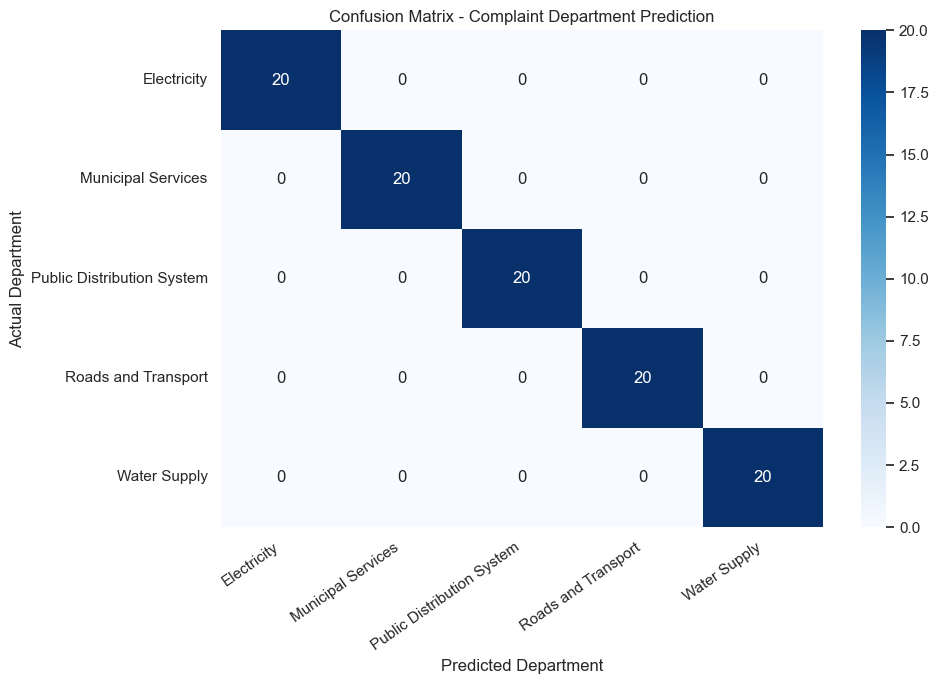

In [5]:
# PHASE 2 - TASK 2.1: MACHINE LEARNING MODEL

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load cleaned dataset
df = pd.read_csv("data/jan_samadhan_cleaned.csv")

# Input feature and target
X = df["complaint_description"]
y = df["department"]

# Split dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into numerical TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

# Predict departments for test data
y_pred = model.predict(X_test_tfidf)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("MACHINE LEARNING MODEL TRAINED SUCCESSFULLY")
print("-------------------------------------------")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix - Complaint Department Prediction")
plt.xlabel("Predicted Department")
plt.ylabel("Actual Department")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "outputs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# PHASE 2 - TASK 2.2: TEST WITH A NEW COMPLAINT

# New citizen complaint
new_complaint = [
    "There has been no water supply in our village for five days. "
    "People are facing difficulties. Please resolve this issue."
]

# Convert complaint into TF-IDF features
new_complaint_tfidf = vectorizer.transform(new_complaint)

# Predict department
predicted_department = model.predict(new_complaint_tfidf)

print("JAN-SAMADHAN - COMPLAINT ROUTING SYSTEM")
print("----------------------------------------")
print("Citizen Complaint:")
print(new_complaint[0])

print("\nPredicted Department:")
print(predicted_department[0])

# Show prediction probabilities
probabilities = model.predict_proba(new_complaint_tfidf)[0]

print("\nDepartment-wise prediction confidence:")

for department, probability in sorted(
    zip(model.classes_, probabilities),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{department}: {probability * 100:.2f}%")
    

JAN-SAMADHAN - COMPLAINT ROUTING SYSTEM
----------------------------------------
Citizen Complaint:
There has been no water supply in our village for five days. People are facing difficulties. Please resolve this issue.

Predicted Department:
Water Supply

Department-wise prediction confidence:
Water Supply: 79.16%
Roads and Transport: 6.13%
Municipal Services: 5.84%
Electricity: 4.58%
Public Distribution System: 4.30%


In [7]:
# SAVED

import joblib
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

joblib.dump(model, "outputs/jan_samadhan_model.pkl")
joblib.dump(vectorizer, "outputs/tfidf_vectorizer.pkl")

print("MODEL SAVED SUCCESSFULLY")
print("-------------------------")
print("1. jan_samadhan_model.pkl")
print("2. tfidf_vectorizer.pkl")

MODEL SAVED SUCCESSFULLY
-------------------------
1. jan_samadhan_model.pkl
2. tfidf_vectorizer.pkl


Why Logistic Regression instead of Deep Learning?
Logistic Regression is selected because it is lightweight, computationally efficient and suitable for text classification when combined with TF-IDF features. It can perform well on small and medium-sized datasets without requiring expensive GPU resources. Training a deep neural network or BERT model from scratch would require substantially more data, computing power and training time. Therefore, Logistic Regression is a practical choice for this proof of concept.

In [8]:
import joblib

# Load saved model and vectorizer
loaded_model = joblib.load("outputs/jan_samadhan_model.pkl")
loaded_vectorizer = joblib.load("outputs/tfidf_vectorizer.pkl")

# Test prediction
test_complaint = [
    "There is no electricity supply in our village."
]

test_features = loaded_vectorizer.transform(test_complaint)

prediction = loaded_model.predict(test_features)

print("Saved model loaded successfully!")
print("Predicted Department:", prediction[0])

Saved model loaded successfully!
Predicted Department: Water Supply


In [9]:
# TEST MODEL WITH DIFFERENT COMPLAINTS

test_complaints = [
    "There has been a power outage in our locality for many hours.",
    "There has been no water supply in our locality for several days.",
    "The main road in our village is damaged and full of potholes.",
    "Garbage has not been collected from our locality for many days."
]

test_features = loaded_vectorizer.transform(test_complaints)
predictions = loaded_model.predict(test_features)

for complaint, prediction in zip(test_complaints, predictions):
    print("Complaint:", complaint)
    print("Predicted Department:", prediction)
    print("-" * 70)

Complaint: There has been a power outage in our locality for many hours.
Predicted Department: Electricity
----------------------------------------------------------------------
Complaint: There has been no water supply in our locality for several days.
Predicted Department: Water Supply
----------------------------------------------------------------------
Complaint: The main road in our village is damaged and full of potholes.
Predicted Department: Roads and Transport
----------------------------------------------------------------------
Complaint: Garbage has not been collected from our locality for many days.
Predicted Department: Municipal Services
----------------------------------------------------------------------


## PHASE 3: GENERATIVE AI AND OFFICER CO-PILOT

### C.R.O.S.S. Prompt Engineering Framework

- Context: Government citizen grievance redressal system.
- Role: AI assistant supporting government grievance officers.
- Objective: Summarize complaints, assess sentiment and urgency, and draft acknowledgment letters.
- Style: Neutral, empathetic, professional and government-appropriate.
- Structure: Two-sentence summary, sentiment, urgency and acknowledgment letter.

The system is designed to assist officers. Final decisions and official responses must be reviewed by authorized human officers.

In [10]:
# PHASE 3 - TASK 3.1: C.R.O.S.S. FRAMEWORK

def jan_samadhan_copilot(complaint):

    # C - CONTEXT
    context = (
        "Government citizen grievance redressal system "
        "supporting public grievance officers."
    )

    # R - ROLE
    role = (
        "You are Jan-Samadhan, an empathetic and professional "
        "government grievance assistance system."
    )

    # O - OBJECTIVE
    objective = (
        "Analyze the complaint, summarize it, assess sentiment "
        "and urgency, and prepare an acknowledgment letter."
    )

    # S - STYLE
    style = (
        "Use neutral, polite, simple and professional language."
    )

    # S - STRUCTURE
    structure = (
        "Provide a two-sentence summary, sentiment, urgency "
        "and a polite acknowledgment letter."
    )

    # Combined C.R.O.S.S. prompt
    cross_prompt = f"""
    CONTEXT: {context}
    ROLE: {role}
    OBJECTIVE: {objective}
    STYLE: {style}
    STRUCTURE: {structure}

    CITIZEN COMPLAINT:
    {complaint}
    """

    # Simple rule-based demonstration
    text = complaint.lower()

    # Sentiment assessment
    angry_words = [
        "angry", "frustrated", "disappointed",
        "unacceptable", "worst", "irresponsible",
        "ignored", "fed up"
    ]

    if any(word in text for word in angry_words):
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    # Urgency assessment
    high_words = [
        "emergency", "urgent", "danger",
        "immediately", "life threatening"
    ]

    medium_words = [
        "several days", "many days",
        "weeks", "pending", "not working"
    ]

    if any(word in text for word in high_words):
        urgency = "High"
    elif any(word in text for word in medium_words):
        urgency = "Medium"
    else:
        urgency = "Low"

    # Two-sentence neutral summary
    summary = (
        "The citizen has reported a public service-related problem "
        "and requested intervention from the concerned department. "
        "The grievance requires examination and appropriate action "
        "by the responsible authority."
    )

    # Acknowledgment letter
    acknowledgment = f"""
    Subject: Acknowledgment of Your Grievance

    Dear Citizen,

    We acknowledge receipt of your grievance.

    Your complaint has been recorded for examination by the
    concerned department. The matter will be reviewed and
    necessary action will be taken as per applicable rules.

    Thank you for bringing this matter to our attention.

    Regards,
    Grievance Redressal Officer
    """

    return {
        "CROSS_Prompt": cross_prompt,
        "Summary": summary,
        "Sentiment": sentiment,
        "Urgency": urgency,
        "Acknowledgment_Letter": acknowledgment
    }


# Test with an angry citizen complaint
sample_complaint = """
I am extremely frustrated and angry because there has been
no drinking water in our village for several days.
The authorities have ignored our complaints.
This is unacceptable. Please resolve this issue immediately.
"""

result = jan_samadhan_copilot(sample_complaint)

print("JAN-SAMADHAN OFFICER CO-PILOT")
print("=" * 60)

print("\nC.R.O.S.S. PROMPT:")
print(result["CROSS_Prompt"])

print("\nNEUTRAL SUMMARY:")
print(result["Summary"])

print("\nSENTIMENT:")
print(result["Sentiment"])

print("\nURGENCY:")
print(result["Urgency"])

print("\nACKNOWLEDGMENT LETTER:")
print(result["Acknowledgment_Letter"])

JAN-SAMADHAN OFFICER CO-PILOT

C.R.O.S.S. PROMPT:

    CONTEXT: Government citizen grievance redressal system supporting public grievance officers.
    ROLE: You are Jan-Samadhan, an empathetic and professional government grievance assistance system.
    OBJECTIVE: Analyze the complaint, summarize it, assess sentiment and urgency, and prepare an acknowledgment letter.
    STYLE: Use neutral, polite, simple and professional language.
    STRUCTURE: Provide a two-sentence summary, sentiment, urgency and a polite acknowledgment letter.

    CITIZEN COMPLAINT:
    
I am extremely frustrated and angry because there has been
no drinking water in our village for several days.
The authorities have ignored our complaints.
This is unacceptable. Please resolve this issue immediately.

    

NEUTRAL SUMMARY:
The citizen has reported a public service-related problem and requested intervention from the concerned department. The grievance requires examination and appropriate action by the responsible

In [11]:
# PHASE 4 - TASK 4.1: PERSONAL INFORMATION MASKING

import re

def mask_pii(text):

    # Mask Aadhaar-like 12-digit numbers
    text = re.sub(
        r"\b\d{4}\s?\d{4}\s?\d{4}\b",
        "[AADHAAR MASKED]",
        text
    )

    # Mask Indian mobile numbers
    text = re.sub(
        r"(?<!\d)(?:\+91[-\s]?)?[6-9]\d{9}(?!\d)",
        "[PHONE MASKED]",
        text
    )

    # Mask email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "[EMAIL MASKED]",
        text
    )

    # Mask simple Indian PIN codes
    text = re.sub(
        r"\bPIN\s*[:\-]?\s*\d{6}\b",
        "PIN [MASKED]",
        text,
        flags=re.IGNORECASE
    )

    return text


# Sample complaint containing synthetic personal information
sample_pii_complaint = """
I am facing a water supply problem.
My Aadhaar number is 1234 5678 9012.
My mobile number is 9876543210.
Please contact me at sunny@example.com.
My address PIN is 233001.
"""

masked_complaint = mask_pii(sample_pii_complaint)

print("ORIGINAL COMPLAINT:")
print(sample_pii_complaint)

print("\nCOMPLAINT AFTER PII MASKING:")
print(masked_complaint)

ORIGINAL COMPLAINT:

I am facing a water supply problem.
My Aadhaar number is 1234 5678 9012.
My mobile number is 9876543210.
Please contact me at sunny@example.com.
My address PIN is 233001.


COMPLAINT AFTER PII MASKING:

I am facing a water supply problem.
My Aadhaar number is [AADHAAR MASKED].
My mobile number is [PHONE MASKED].
Please contact me at [EMAIL MASKED].
My address PIN is 233001.



In [12]:
import re

def mask_pii(text):

    # Mask Aadhaar number
    text = re.sub(
        r"\b\d{4}\s?\d{4}\s?\d{4}\b",
        "[AADHAAR MASKED]",
        text
    )

    # Mask Indian mobile number
    text = re.sub(
        r"(?<!\d)(?:\+91[-\s]?)?[6-9]\d{9}(?!\d)",
        "[PHONE MASKED]",
        text
    )

    # Mask email
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "[EMAIL MASKED]",
        text
    )

    # Mask PIN code, including formats such as:
    # PIN 233001, PIN: 233001, PIN is 233001
    text = re.sub(
        r"\bPIN\s*(?:is\s*)?[:\-]?\s*\d{6}\b",
        "PIN [MASKED]",
        text,
        flags=re.IGNORECASE
    )

    return text


# Test again
masked_complaint = mask_pii(sample_pii_complaint)

print("CORRECTED PII MASKING RESULT:")
print(masked_complaint)

CORRECTED PII MASKING RESULT:

I am facing a water supply problem.
My Aadhaar number is [AADHAAR MASKED].
My mobile number is [PHONE MASKED].
Please contact me at [EMAIL MASKED].
My address PIN [MASKED].



## PHASE 4: GOVERNANCE, ETHICS AND SECURITY

### 1. Privacy and PII Protection
Personal information such as Aadhaar numbers, mobile numbers,
email addresses and PIN codes is masked before processing
complaints through external AI services.

### 2. Risk Assessment

**Risk 1: Prompt Injection**

A citizen may include malicious instructions inside a complaint
to manipulate the AI system.

Mitigation:
- Treat complaint text strictly as untrusted input.
- Do not execute instructions found inside complaints.
- Restrict AI output to predefined tasks.
- Require human officer review before official action.

**Risk 2: Regional Language Misclassification**

Complaints written in Hindi or other regional languages may be
misclassified by an English-focused model.

Mitigation:
- Use multilingual NLP models.
- Validate predictions using regional-language test datasets.
- Provide manual review for low-confidence predictions.
- Allow officers to correct department classifications.

### 3. Human Oversight

AI-generated summaries, urgency assessments and acknowledgment
drafts must be reviewed by authorized government officers.
The AI system must not independently approve or reject grievances.

In [13]:
import re

def mask_pii(text):

    # Aadhaar
    text = re.sub(
        r"\b\d{4}\s?\d{4}\s?\d{4}\b",
        "[AADHAAR MASKED]", text
    )

    # Indian mobile number
    text = re.sub(
        r"(?<!\d)(?:\+91[-\s]?)?[6-9]\d{9}(?!\d)",
        "[PHONE MASKED]", text
    )

    # Email
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "[EMAIL MASKED]", text
    )

    # Home address following Address:
    text = re.sub(
        r"(?im)(address\s*:\s*).+",
        r"\1[ADDRESS MASKED]",
        text
    )

    # PIN code
    text = re.sub(
        r"\bPIN\s*(?:is\s*)?[:\-]?\s*\d{6}\b",
        "PIN [MASKED]",
        text,
        flags=re.IGNORECASE
    )

    return text


test_text = """
My Aadhaar is 1234 5678 9012.
My phone is 9876543210.
Email: sunny@example.com.
Address: House 12, Village Rampur, Ghazipur, Uttar Pradesh.
PIN is 233001.
"""

print(mask_pii(test_text))


My Aadhaar is [AADHAAR MASKED].
My phone is [PHONE MASKED].
Email: [EMAIL MASKED].
Address: [ADDRESS MASKED]
PIN [MASKED].



## PHASE 3 - TASK 3.2: MINI-RAG SIMULATION

### Knowledge Base: Citizen Water Supply Grievance SOP

Document Type: Fictional Standard Operating Procedure (SOP)
Purpose: Demonstration of Retrieval-Augmented Generation (RAG).

Guidelines:
1. Citizens may submit water supply complaints through the grievance portal or the concerned local office.
2. Each complaint should include the locality, description of the problem and contact details.
3. The concerned department should acknowledge receipt of a complaint within 3 working days.
4. The department should inspect reported water pipeline leakage and supply disruptions.
5. If drinking water contamination is reported, the complaint should be escalated for priority inspection.
6. The officer should update the grievance record with the action taken and resolution status.
7. If the supplied guidelines do not contain an answer, the system must refer the matter to an authorized officer.

In [14]:
# PHASE 3 - TASK 3.2: MINI-RAG SIMULATION

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Fictional SOP knowledge base
sop_documents = [
    "Citizens may submit water supply complaints through the grievance portal or the concerned local office.",

    "Each complaint should include the locality, description of the problem and contact details.",

    "The concerned department should acknowledge receipt of a complaint within 3 working days.",

    "The department should inspect reported water pipeline leakage and supply disruptions.",

    "If drinking water contamination is reported, the complaint should be escalated for priority inspection.",

    "The officer should update the grievance record with the action taken and resolution status.",

    "If the supplied guidelines do not contain an answer, the system must refer the matter to an authorized officer."
]

# Create TF-IDF knowledge base
rag_vectorizer = TfidfVectorizer(stop_words="english")

sop_vectors = rag_vectorizer.fit_transform(sop_documents)


# Retrieval function
def retrieve_sop_information(question):

    question_vector = rag_vectorizer.transform([question])

    similarities = cosine_similarity(
        question_vector,
        sop_vectors
    )[0]

    best_index = similarities.argmax()
    best_score = similarities[best_index]

    if best_score < 0.10:
        return None, best_score

    return sop_documents[best_index], best_score


# Citizen question
citizen_question = (
    "I have no water supply in my locality. "
    "How many days does the department have to acknowledge my complaint?"
)

# Retrieve relevant SOP information
retrieved_context, similarity_score = retrieve_sop_information(
    citizen_question
)

print("JAN-SAMADHAN MINI-RAG SYSTEM")
print("=" * 55)

print("\nCITIZEN QUESTION:")
print(citizen_question)

print("\nRETRIEVED SOP INFORMATION:")
print(retrieved_context)

print("\nRETRIEVAL SIMILARITY SCORE:")
print(f"{similarity_score:.2f}")

# Generate a grounded response using retrieved information
print("\nOFFICER CO-PILOT RESPONSE:")

if retrieved_context is None:
    print(
        "The supplied SOP does not contain sufficient information "
        "to answer this question. Please refer it to an authorized officer."
    )
else:
    print(
        "According to the supplied SOP, "
        + retrieved_context
    )

print("\nSOURCE: Fictional Water Supply Grievance SOP")

JAN-SAMADHAN MINI-RAG SYSTEM

CITIZEN QUESTION:
I have no water supply in my locality. How many days does the department have to acknowledge my complaint?

RETRIEVED SOP INFORMATION:
The concerned department should acknowledge receipt of a complaint within 3 working days.

RETRIEVAL SIMILARITY SCORE:
0.57

OFFICER CO-PILOT RESPONSE:
According to the supplied SOP, The concerned department should acknowledge receipt of a complaint within 3 working days.

SOURCE: Fictional Water Supply Grievance SOP


In [16]:
# PHASE 3 - TASK 3.2: MINI-RAG SIMULATION

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Fictional SOP knowledge base
sop_documents = [
    "Citizens may submit water supply complaints through the grievance portal or the concerned local office.",

    "Each complaint should include the locality, description of the problem and contact details.",

    "The concerned department should acknowledge receipt of a complaint within 3 working days.",

    "The department should inspect reported water pipeline leakage and supply disruptions.",

    "If drinking water contamination is reported, the complaint should be escalated for priority inspection.",

    "The officer should update the grievance record with the action taken and resolution status.",

    "If the supplied guidelines do not contain an answer, the system must refer the matter to an authorized officer."
]

# Create TF-IDF knowledge base
rag_vectorizer = TfidfVectorizer(stop_words="english")

sop_vectors = rag_vectorizer.fit_transform(sop_documents)


# Retrieval function
def retrieve_sop_information(question):

    question_vector = rag_vectorizer.transform([question])

    similarities = cosine_similarity(
        question_vector,
        sop_vectors
    )[0]

    best_index = similarities.argmax()
    best_score = similarities[best_index]

    if best_score < 0.10:
        return None, best_score

    return sop_documents[best_index], best_score


# Citizen question
citizen_question = (
    "What should happen if drinking water is contaminated?"
)


# Retrieve relevant SOP information
retrieved_context, similarity_score = retrieve_sop_information(
    citizen_question
)

print("JAN-SAMADHAN MINI-RAG SYSTEM")
print("=" * 55)

print("\nCITIZEN QUESTION:")
print(citizen_question)

print("\nRETRIEVED SOP INFORMATION:")
print(retrieved_context)

print("\nRETRIEVAL SIMILARITY SCORE:")
print(f"{similarity_score:.2f}")

# Generate a grounded response using retrieved information
print("\nOFFICER CO-PILOT RESPONSE:")

if retrieved_context is None:
    print(
        "The supplied SOP does not contain sufficient information "
        "to answer this question. Please refer it to an authorized officer."
    )
else:
    print(
        "According to the supplied SOP, "
        + retrieved_context
    )

print("\nSOURCE: Fictional Water Supply Grievance SOP")

JAN-SAMADHAN MINI-RAG SYSTEM

CITIZEN QUESTION:
What should happen if drinking water is contaminated?

RETRIEVED SOP INFORMATION:
If drinking water contamination is reported, the complaint should be escalated for priority inspection.

RETRIEVAL SIMILARITY SCORE:
0.47

OFFICER CO-PILOT RESPONSE:
According to the supplied SOP, If drinking water contamination is reported, the complaint should be escalated for priority inspection.

SOURCE: Fictional Water Supply Grievance SOP


In [17]:
# PHASE 3 - TASK 3.2: MINI-RAG SIMULATION

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Fictional SOP knowledge base
sop_documents = [
    "Citizens may submit water supply complaints through the grievance portal or the concerned local office.",

    "Each complaint should include the locality, description of the problem and contact details.",

    "The concerned department should acknowledge receipt of a complaint within 3 working days.",

    "The department should inspect reported water pipeline leakage and supply disruptions.",

    "If drinking water contamination is reported, the complaint should be escalated for priority inspection.",

    "The officer should update the grievance record with the action taken and resolution status.",

    "If the supplied guidelines do not contain an answer, the system must refer the matter to an authorized officer."
]

# Create TF-IDF knowledge base
rag_vectorizer = TfidfVectorizer(stop_words="english")

sop_vectors = rag_vectorizer.fit_transform(sop_documents)


# Retrieval function
def retrieve_sop_information(question):

    question_vector = rag_vectorizer.transform([question])

    similarities = cosine_similarity(
        question_vector,
        sop_vectors
    )[0]

    best_index = similarities.argmax()
    best_score = similarities[best_index]

    if best_score < 0.10:
        return None, best_score

    return sop_documents[best_index], best_score


# Citizen question
citizen_question = (
    "What is the compensation amount for a delayed water connection?"
)



# Retrieve relevant SOP information
retrieved_context, similarity_score = retrieve_sop_information(
    citizen_question
)

print("JAN-SAMADHAN MINI-RAG SYSTEM")
print("=" * 55)

print("\nCITIZEN QUESTION:")
print(citizen_question)

print("\nRETRIEVED SOP INFORMATION:")
print(retrieved_context)

print("\nRETRIEVAL SIMILARITY SCORE:")
print(f"{similarity_score:.2f}")

# Generate a grounded response using retrieved information
print("\nOFFICER CO-PILOT RESPONSE:")

if retrieved_context is None:
    print(
        "The supplied SOP does not contain sufficient information "
        "to answer this question. Please refer it to an authorized officer."
    )
else:
    print(
        "According to the supplied SOP, "
        + retrieved_context
    )

print("\nSOURCE: Fictional Water Supply Grievance SOP")

JAN-SAMADHAN MINI-RAG SYSTEM

CITIZEN QUESTION:
What is the compensation amount for a delayed water connection?

RETRIEVED SOP INFORMATION:
The department should inspect reported water pipeline leakage and supply disruptions.

RETRIEVAL SIMILARITY SCORE:
0.28

OFFICER CO-PILOT RESPONSE:
According to the supplied SOP, The department should inspect reported water pipeline leakage and supply disruptions.

SOURCE: Fictional Water Supply Grievance SOP


In [18]:
# PHASE 3 - TASK 3.2: MINI-RAG SIMULATION

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Fictional SOP knowledge base
sop_documents = [
    "Citizens may submit water supply complaints through the grievance portal or the concerned local office.",

    "Each complaint should include the locality, description of the problem and contact details.",

    "The concerned department should acknowledge receipt of a complaint within 3 working days.",

    "The department should inspect reported water pipeline leakage and supply disruptions.",

    "If drinking water contamination is reported, the complaint should be escalated for priority inspection.",

    "The officer should update the grievance record with the action taken and resolution status.",

    "If the supplied guidelines do not contain an answer, the system must refer the matter to an authorized officer."
]

# Create TF-IDF knowledge base
rag_vectorizer = TfidfVectorizer(stop_words="english")

sop_vectors = rag_vectorizer.fit_transform(sop_documents)


# Retrieval function
def retrieve_sop_information(question):
    question_vector = rag_vectorizer.transform([question])
    similarities = cosine_similarity(question_vector, sop_vectors)[0]

    best_index = similarities.argmax()
    best_score = similarities[best_index]

    # Reject weak or unrelated matches
    if best_score < 0.35:
        return None, best_score

    return sop_documents[best_index], best_score

# Citizen question
citizen_question = (
    "What is the compensation amount for a delayed water connection?"
)



# Retrieve relevant SOP information
retrieved_context, similarity_score = retrieve_sop_information(
    citizen_question
)

print("JAN-SAMADHAN MINI-RAG SYSTEM")
print("=" * 55)

print("\nCITIZEN QUESTION:")
print(citizen_question)

print("\nRETRIEVED SOP INFORMATION:")
print(retrieved_context)

print("\nRETRIEVAL SIMILARITY SCORE:")
print(f"{similarity_score:.2f}")

# Generate a grounded response using retrieved information
print("\nOFFICER CO-PILOT RESPONSE:")

if retrieved_context is None:
    print(
        "The supplied SOP does not contain sufficient information "
        "to answer this question. Please refer it to an authorized officer."
    )
else:
    print(
        "According to the supplied SOP, "
        + retrieved_context
    )

print("\nSOURCE: Fictional Water Supply Grievance SOP")

JAN-SAMADHAN MINI-RAG SYSTEM

CITIZEN QUESTION:
What is the compensation amount for a delayed water connection?

RETRIEVED SOP INFORMATION:
None

RETRIEVAL SIMILARITY SCORE:
0.28

OFFICER CO-PILOT RESPONSE:
The supplied SOP does not contain sufficient information to answer this question. Please refer it to an authorized officer.

SOURCE: Fictional Water Supply Grievance SOP


### Mini-RAG: Working and Limitations

The Mini-RAG system uses TF-IDF vectorization to convert SOP documents and citizen questions into numerical representations. Cosine similarity identifies the most relevant SOP passage for a question. The retrieved passage is then used as the context for generating a constrained response.

The system includes a similarity threshold to reduce irrelevant retrieval. If no sufficiently relevant passage is found, it refers the question to an authorized officer instead of generating an unsupported answer.

This is an offline Mini-RAG simulation using TF-IDF retrieval and template-based responses. It does not use an external Large Language Model (LLM), a production vector database, or generative AI. The SOP used is fictional and created only for demonstration.

In [19]:
# PHASE 3 - TASK 3.2: MINI-RAG SIMULATION

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Fictional SOP knowledge base
sop_documents = [
    "Citizens may submit water supply complaints through the grievance portal or the concerned local office.",

    "Each complaint should include the locality, description of the problem and contact details.",

    "The concerned department should acknowledge receipt of a complaint within 3 working days.",

    "The department should inspect reported water pipeline leakage and supply disruptions.",

    "If drinking water contamination is reported, the complaint should be escalated for priority inspection.",

    "The officer should update the grievance record with the action taken and resolution status.",

    "If the supplied guidelines do not contain an answer, the system must refer the matter to an authorized officer."
]

# Create TF-IDF knowledge base
rag_vectorizer = TfidfVectorizer(stop_words="english")

sop_vectors = rag_vectorizer.fit_transform(sop_documents)


# Retrieval function
def retrieve_sop_information(question):
    question_vector = rag_vectorizer.transform([question])
    similarities = cosine_similarity(question_vector, sop_vectors)[0]

    best_index = similarities.argmax()
    best_score = similarities[best_index]

    # Reject weak or unrelated matches
    if best_score < 0.35:
        return None, best_score

    return sop_documents[best_index], best_score

# Citizen question
citizen_question = "How many days does the department have to acknowledge a complaint?"



# Retrieve relevant SOP information
retrieved_context, similarity_score = retrieve_sop_information(
    citizen_question
)

print("JAN-SAMADHAN MINI-RAG SYSTEM")
print("=" * 55)

print("\nCITIZEN QUESTION:")
print(citizen_question)

print("\nRETRIEVED SOP INFORMATION:")
print(retrieved_context)

print("\nRETRIEVAL SIMILARITY SCORE:")
print(f"{similarity_score:.2f}")

# Generate a grounded response using retrieved information
print("\nOFFICER CO-PILOT RESPONSE:")

if retrieved_context is None:
    print(
        "The supplied SOP does not contain sufficient information "
        "to answer this question. Please refer it to an authorized officer."
    )
else:
    print(
        "According to the supplied SOP, "
        + retrieved_context
    )

print("\nSOURCE: Fictional Water Supply Grievance SOP")

JAN-SAMADHAN MINI-RAG SYSTEM

CITIZEN QUESTION:
How many days does the department have to acknowledge a complaint?

RETRIEVED SOP INFORMATION:
The concerned department should acknowledge receipt of a complaint within 3 working days.

RETRIEVAL SIMILARITY SCORE:
0.74

OFFICER CO-PILOT RESPONSE:
According to the supplied SOP, The concerned department should acknowledge receipt of a complaint within 3 working days.

SOURCE: Fictional Water Supply Grievance SOP


In [20]:
# PHASE 3 - TASK 3.2: MINI-RAG SIMULATION

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Fictional SOP knowledge base
sop_documents = [
    "Citizens may submit water supply complaints through the grievance portal or the concerned local office.",

    "Each complaint should include the locality, description of the problem and contact details.",

    "The concerned department should acknowledge receipt of a complaint within 3 working days.",

    "The department should inspect reported water pipeline leakage and supply disruptions.",

    "If drinking water contamination is reported, the complaint should be escalated for priority inspection.",

    "The officer should update the grievance record with the action taken and resolution status.",

    "If the supplied guidelines do not contain an answer, the system must refer the matter to an authorized officer."
]

# Create TF-IDF knowledge base
rag_vectorizer = TfidfVectorizer(stop_words="english")

sop_vectors = rag_vectorizer.fit_transform(sop_documents)


# Retrieval function
def retrieve_sop_information(question):
    question_vector = rag_vectorizer.transform([question])
    similarities = cosine_similarity(question_vector, sop_vectors)[0]

    best_index = similarities.argmax()
    best_score = similarities[best_index]

    # Reject weak or unrelated matches
    if best_score < 0.35:
        return None, best_score

    return sop_documents[best_index], best_score

# Citizen question
citizen_question = "What happens if drinking water is contaminated?"



# Retrieve relevant SOP information
retrieved_context, similarity_score = retrieve_sop_information(
    citizen_question
)

print("JAN-SAMADHAN MINI-RAG SYSTEM")
print("=" * 55)

print("\nCITIZEN QUESTION:")
print(citizen_question)

print("\nRETRIEVED SOP INFORMATION:")
print(retrieved_context)

print("\nRETRIEVAL SIMILARITY SCORE:")
print(f"{similarity_score:.2f}")

# Generate a grounded response using retrieved information
print("\nOFFICER CO-PILOT RESPONSE:")

if retrieved_context is None:
    print(
        "The supplied SOP does not contain sufficient information "
        "to answer this question. Please refer it to an authorized officer."
    )
else:
    print(
        "According to the supplied SOP, "
        + retrieved_context
    )

print("\nSOURCE: Fictional Water Supply Grievance SOP")

JAN-SAMADHAN MINI-RAG SYSTEM

CITIZEN QUESTION:
What happens if drinking water is contaminated?

RETRIEVED SOP INFORMATION:
If drinking water contamination is reported, the complaint should be escalated for priority inspection.

RETRIEVAL SIMILARITY SCORE:
0.47

OFFICER CO-PILOT RESPONSE:
According to the supplied SOP, If drinking water contamination is reported, the complaint should be escalated for priority inspection.

SOURCE: Fictional Water Supply Grievance SOP


# PROJECT CONCLUSION: JAN-SAMADHAN

The Jan-Samadhan project demonstrates how Artificial Intelligence and Machine Learning can support citizen grievance redressal.

The project includes:
1. Data preprocessing and exploratory data analysis using Pandas.
2. Complaint classification using TF-IDF and Logistic Regression.
3. C.R.O.S.S.-based prompt engineering for complaint analysis.
4. Mini-RAG simulation using TF-IDF retrieval and cosine similarity.
5. Personally Identifiable Information (PII) masking using regular expressions.
6. AI risk assessment covering prompt injection and regional-language misclassification.

The system demonstrates how AI-assisted tools can help government departments categorize complaints, understand citizen concerns, retrieve relevant guidelines and protect sensitive information.

### Limitations
- The dataset contains 500 synthetically generated complaints.
- The SOP is fictional and intended only for demonstration.
- The Mini-RAG uses offline TF-IDF retrieval and template-based responses, not a live generative LLM.
- The classification model requires validation using real-world data before deployment.
- Human verification is necessary before official grievance decisions.

### Future Scope
- Integration with a government grievance portal.
- Support for Hindi and other regional languages.
- Integration with an authorized LLM and verified government SOP documents.
- Dashboard for grievance monitoring and departmental performance.
- Role-based access and secure audit logging.